In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import matplotlib.gridspec as gridspec

# Set up the plotting style
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
# =============================================================================
# PART (a) - 1D Convolution of rectangular signal and exponential decay
# =============================================================================

def part_a():
    # Define parameters
    L = 5  # Length of rectangular signal
    n_start, n_end = -6, 12
    n = np.arange(n_start, n_end + 1)
    
    # Define x(n) - rectangular signal
    x = np.zeros_like(n, dtype=float)
    x[(n >= 0) & (n < L)] = 1
    
    # Define h(n) - exponential decay
    h = np.zeros_like(n, dtype=float)
    mask_h = n >= 0
    h[mask_h] = (0.5) ** n[mask_h]
    
    # Compute convolution
    y = np.convolve(x, h, mode='full')
    # Adjust n indices for convolution result
    n_conv = np.arange(2 * n_start, 2 * n_end + 1)
    n_conv = n_conv[:len(y)]  # Ensure same length
    
    # Create the plot
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10))
    
    # Plot x(n)
    ax1.stem(n, x, linefmt='b-', markerfmt='bo', basefmt='k-')
    ax1.set_title('(a) Input Signal x[n] - Rectangular Pulse', fontsize=14)
    ax1.set_ylabel('Amplitude', fontsize=12)
    ax1.set_xlabel('n', fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim(n_start, n_end)
    
    # Plot h(n)
    ax2.stem(n, h, linefmt='r-', markerfmt='ro', basefmt='k-')
    ax2.set_title('Impulse Response h[n] - Exponential Decay', fontsize=14)
    ax2.set_ylabel('Amplitude', fontsize=12)
    ax2.set_xlabel('n', fontsize=12)
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(n_start, n_end)
    
    # Plot y(n)
    ax3.stem(n_conv, y, linefmt='g-', markerfmt='go', basefmt='k-')
    ax3.set_title('Convolution Output y[n] = x[n] * h[n]', fontsize=14)
    ax3.set_ylabel('Amplitude', fontsize=12)
    ax3.set_xlabel('n', fontsize=12)
    ax3.grid(True, alpha=0.3)
    ax3.set_xlim(n_start, n_end)
    
    plt.tight_layout()
    plt.show()
    
    return x, h, y, n, n_conv

In [3]:
# =============================================================================
# PART (b) - Time-shifted convolution
# =============================================================================

def part_b():
    # Define parameters
    L = 5
    N_shift = 5
    n_start, n_end = -6, 20
    n = np.arange(n_start, n_end + 1)
    
    # Original x(n)
    x = np.zeros_like(n, dtype=float)
    x[(n >= 0) & (n < L)] = 1
    
    # Shifted x2(n) = x(n - 5)
    x2 = np.zeros_like(n, dtype=float)
    x2[(n >= N_shift) & (n < N_shift + L)] = 1
    
    # Impulse response h(n)
    h = np.zeros_like(n, dtype=float)
    mask_h = n >= 0
    h[mask_h] = (0.5) ** n[mask_h]
    
    # Compute convolutions
    y = np.convolve(x, h, mode='full')
    y2 = np.convolve(x2, h, mode='full')
    
    # Adjust indices
    n_conv = np.arange(2 * n_start, 2 * n_end + 1)
    n_conv = n_conv[:len(y)]
    
    # Create plot
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12))
    
    # Plot original and shifted signals
    ax1.stem(n, x, linefmt='b-', markerfmt='bo', basefmt='k-', label='x[n]')
    ax1.stem(n, x2, linefmt='r--', markerfmt='rx', basefmt='k-', label='x₂[n] = x[n-5]')
    ax1.set_title('(b) Original and Time-Shifted Input Signals', fontsize=14)
    ax1.set_ylabel('Amplitude', fontsize=12)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim(n_start, n_end)
    
    # Plot both convolution results
    ax2.stem(n_conv, y, linefmt='b-', markerfmt='bo', basefmt='k-', label='y[n]')
    ax2.stem(n_conv, y2, linefmt='r--', markerfmt='rx', basefmt='k-', label='y₂[n]')
    ax2.set_title('Convolution Results', fontsize=14)
    ax2.set_ylabel('Amplitude', fontsize=12)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(n_start, n_end)
    
    # Plot to demonstrate time-invariance: y2[n] vs y[n-5]
    y_shifted = np.zeros_like(y2)
    y_shifted[N_shift:] = y[:-N_shift] if len(y) > N_shift else 0
    
    ax3.stem(n_conv, y2, linefmt='r-', markerfmt='ro', basefmt='k-', label='y₂[n] = x₂[n] * h[n]')
    ax3.stem(n_conv, y_shifted, linefmt='g--', markerfmt='gx', basefmt='k-', 
             label='y[n-5] (shifted original)')
    ax3.set_title('Demonstrating Time-Invariance: y₂[n] = y[n-5]', fontsize=14)
    ax3.set_ylabel('Amplitude', fontsize=12)
    ax3.set_xlabel('n', fontsize=12)
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.set_xlim(n_start, n_end)
    
    plt.tight_layout()
    plt.show()
    
    return x, x2, h, y, y2

In [4]:
# =============================================================================
# PART (c) - 2D Convolution
# =============================================================================

def part_c():
    # Define the input matrix x
    x = np.array([
        [1, 2, 3, 4, 5],
        [6, 7, 8, 9, 10],
        [11, 12, 13, 14, 15],
        [16, 17, 18, 19, 20],
        [21, 22, 23, 24, 25]
    ], dtype=float)
    
    # Define the filter h (Sobel-like filter)
    h = np.array([
        [-1, -2, -1],
        [0, 0, 0],
        [1, 2, 1]
    ], dtype=float)
    
    # For true convolution, we need to flip the kernel
    h_flipped = np.flipud(np.fliplr(h))
    
    # Perform 2D convolution
    y = signal.convolve2d(x, h_flipped, mode='valid')
    
    # Create visualization
    fig = plt.figure(figsize=(15, 5))
    
    # Plot input matrix
    ax1 = plt.subplot(131)
    im1 = ax1.imshow(x, cmap='viridis', interpolation='nearest')
    ax1.set_title('(c) Input Matrix x[m,n]', fontsize=14)
    ax1.set_xlabel('n (columns)')
    ax1.set_ylabel('m (rows)')
    plt.colorbar(im1, ax=ax1)
    
    # Add text annotations for x
    for i in range(x.shape[0]):
        for j in range(x.shape[1]):
            ax1.text(j, i, f'{int(x[i,j])}', ha='center', va='center', 
                    color='white' if x[i,j] > 12.5 else 'black', fontweight='bold')
    
    # Plot filter
    ax2 = plt.subplot(132)
    im2 = ax2.imshow(h, cmap='coolwarm', interpolation='nearest')
    ax2.set_title('Filter h[m,n]', fontsize=14)
    ax2.set_xlabel('n (columns)')
    ax2.set_ylabel('m (rows)')
    plt.colorbar(im2, ax=ax2)
    
    # Add text annotations for h
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            ax2.text(j, i, f'{h[i,j]:.0f}', ha='center', va='center', 
                    color='white' if abs(h[i,j]) > 1 else 'black', fontweight='bold')
    
    # Plot output
    ax3 = plt.subplot(133)
    im3 = ax3.imshow(y, cmap='plasma', interpolation='nearest')
    ax3.set_title('Convolution Output y[m,n]', fontsize=14)
    ax3.set_xlabel('n (columns)')
    ax3.set_ylabel('m (rows)')
    plt.colorbar(im3, ax=ax3)
    
    # Add text annotations for y
    for i in range(y.shape[0]):
        for j in range(y.shape[1]):
            ax3.text(j, i, f'{int(y[i,j])}', ha='center', va='center', 
                    color='white' if y[i,j] < -20 else 'black', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    print("Input matrix x:")
    print(x)
    print("\nFilter h:")
    print(h)
    print("\nConvolution result y:")
    print(y)
    
    return x, h, y

In [5]:
# =============================================================================
# PART (d) - 2D Convolution with Striding and Padding
# =============================================================================

def part_d():
    # Define the input matrix x (same as part c)
    x = np.array([
        [1, 2, 3, 4, 5],
        [6, 7, 8, 9, 10],
        [11, 12, 13, 14, 15],
        [16, 17, 18, 19, 20],
        [21, 22, 23, 24, 25]
    ], dtype=float)
    
    # Define the filter h (same as part c)
    h = np.array([
        [-1, -2, -1],
        [0, 0, 0],
        [1, 2, 1]
    ], dtype=float)
    
    # Flip for convolution
    h_flipped = np.flipud(np.fliplr(h))
    
    # Case i: stride=1, pad=1
    x_padded1 = np.pad(x, pad_width=1, mode='constant', constant_values=0)
    y1 = signal.convolve2d(x_padded1, h_flipped, mode='valid')
    
    # Case ii: stride=2, pad=1  
    x_padded2 = np.pad(x, pad_width=1, mode='constant', constant_values=0)
    # For stride=2, we manually select every other element
    y_full = signal.convolve2d(x_padded2, h_flipped, mode='valid')
    y2 = y_full[::2, ::2]  # Apply stride=2
    
    # Create visualization
    fig = plt.figure(figsize=(16, 6))
    
    # Case i: stride=1, pad=1
    ax1 = plt.subplot(231)
    im1 = ax1.imshow(x_padded1, cmap='viridis', interpolation='nearest')
    ax1.set_title('(d-i) Padded Input (pad=1)', fontsize=12)
    ax1.set_xlabel('Columns')
    ax1.set_ylabel('Rows')
    plt.colorbar(im1, ax=ax1)
    
    # Add values to padded input
    for i in range(x_padded1.shape[0]):
        for j in range(x_padded1.shape[1]):
            ax1.text(j, i, f'{int(x_padded1[i,j])}', ha='center', va='center', 
                    color='white' if x_padded1[i,j] > 12.5 else 'black', 
                    fontsize=8, fontweight='bold')
    
    ax2 = plt.subplot(234)
    im2 = ax2.imshow(y1, cmap='plasma', interpolation='nearest')
    ax2.set_title('Output: stride=1, pad=1', fontsize=12)
    ax2.set_xlabel('Columns')
    ax2.set_ylabel('Rows')
    plt.colorbar(im2, ax=ax2)
    
    # Add values to output
    for i in range(y1.shape[0]):
        for j in range(y1.shape[1]):
            ax2.text(j, i, f'{int(y1[i,j])}', ha='center', va='center', 
                    color='white' if y1[i,j] < 0 else 'black', 
                    fontsize=8, fontweight='bold')
    
    # Case ii: stride=2, pad=1
    ax3 = plt.subplot(232)
    im3 = ax3.imshow(x_padded2, cmap='viridis', interpolation='nearest')
    ax3.set_title('(d-ii) Padded Input (pad=1)', fontsize=12)
    ax3.set_xlabel('Columns')
    ax3.set_ylabel('Rows')
    plt.colorbar(im3, ax=ax3)
    
    # Add values to padded input
    for i in range(x_padded2.shape[0]):
        for j in range(x_padded2.shape[1]):
            ax3.text(j, i, f'{int(x_padded2[i,j])}', ha='center', va='center', 
                    color='white' if x_padded2[i,j] > 12.5 else 'black', 
                    fontsize=8, fontweight='bold')
    
    ax4 = plt.subplot(235)
    im4 = ax4.imshow(y_full, cmap='plasma', interpolation='nearest', alpha=0.3)
    # Highlight the strided selection
    y2_display = np.full_like(y_full, np.nan)
    y2_display[::2, ::2] = y_full[::2, ::2]
    im5 = ax4.imshow(y2_display, cmap='plasma', interpolation='nearest')
    ax4.set_title('Output: stride=2, pad=1\n(gray=skipped, colored=selected)', fontsize=12)
    ax4.set_xlabel('Columns')
    ax4.set_ylabel('Rows')
    plt.colorbar(im5, ax=ax4)
    
    # Final output for case ii
    ax5 = plt.subplot(236)
    im6 = ax5.imshow(y2, cmap='plasma', interpolation='nearest')
    ax5.set_title('Final Output after Striding', fontsize=12)
    ax5.set_xlabel('Columns')
    ax5.set_ylabel('Rows')
    plt.colorbar(im6, ax=ax5)
    
    # Add values to final strided output
    for i in range(y2.shape[0]):
        for j in range(y2.shape[1]):
            ax5.text(j, i, f'{int(y2[i,j])}', ha='center', va='center', 
                    color='white' if y2[i,j] < 0 else 'black', 
                    fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    print("Case i - stride=1, pad=1:")
    print("Output shape:", y1.shape)
    print("Output matrix:")
    print(y1)
    
    print("\nCase ii - stride=2, pad=1:")
    print("Output shape:", y2.shape)
    print("Output matrix:")
    print(y2)
    
    return y1, y2

Generating all convolution plots...

1. Part (a): 1D Convolution of rectangular signal and exponential decay


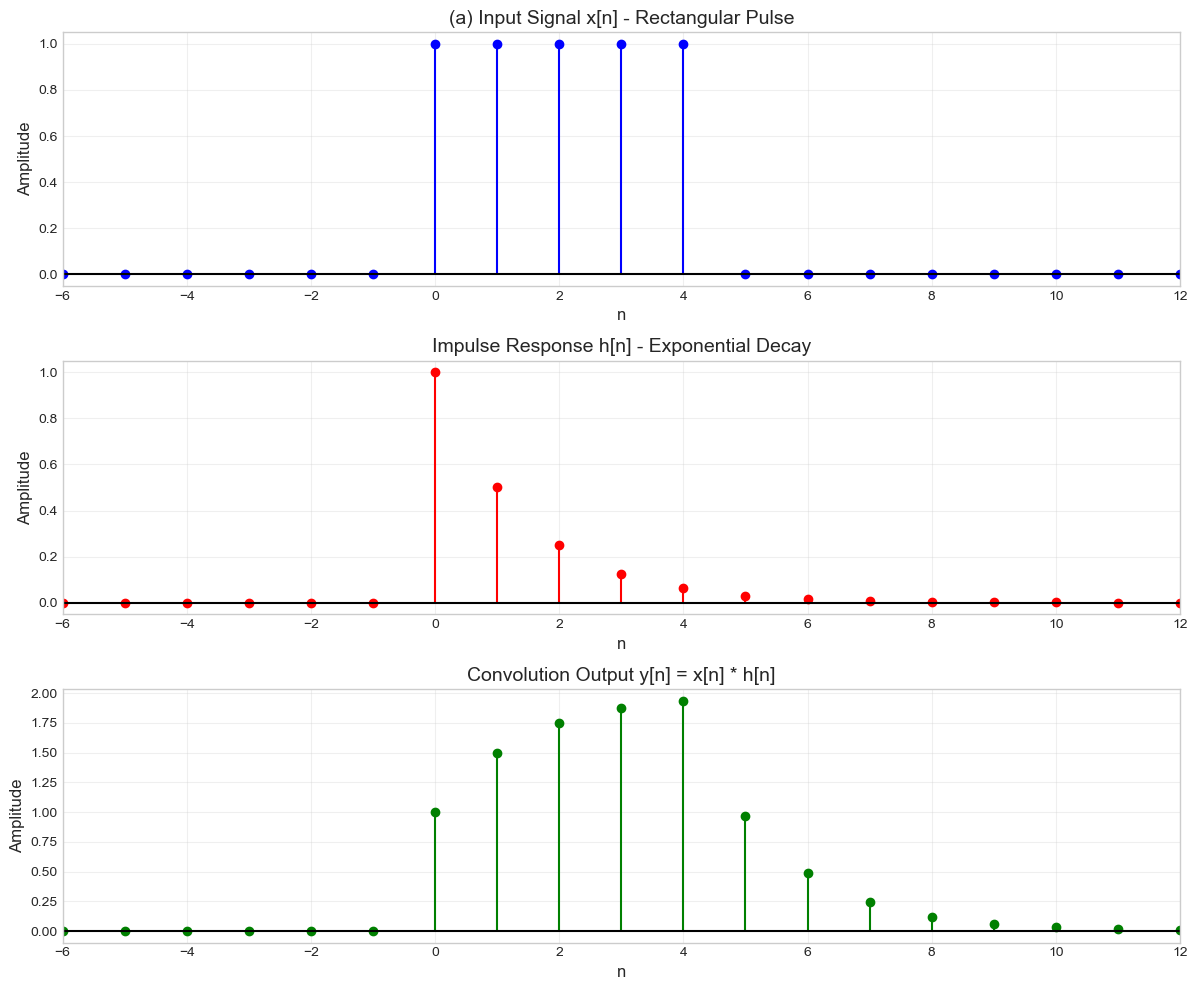


2. Part (b): Time-shifted convolution demonstration


C:\Users\19927\AppData\Local\Temp\ipykernel_34704\1200369172.py:68: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


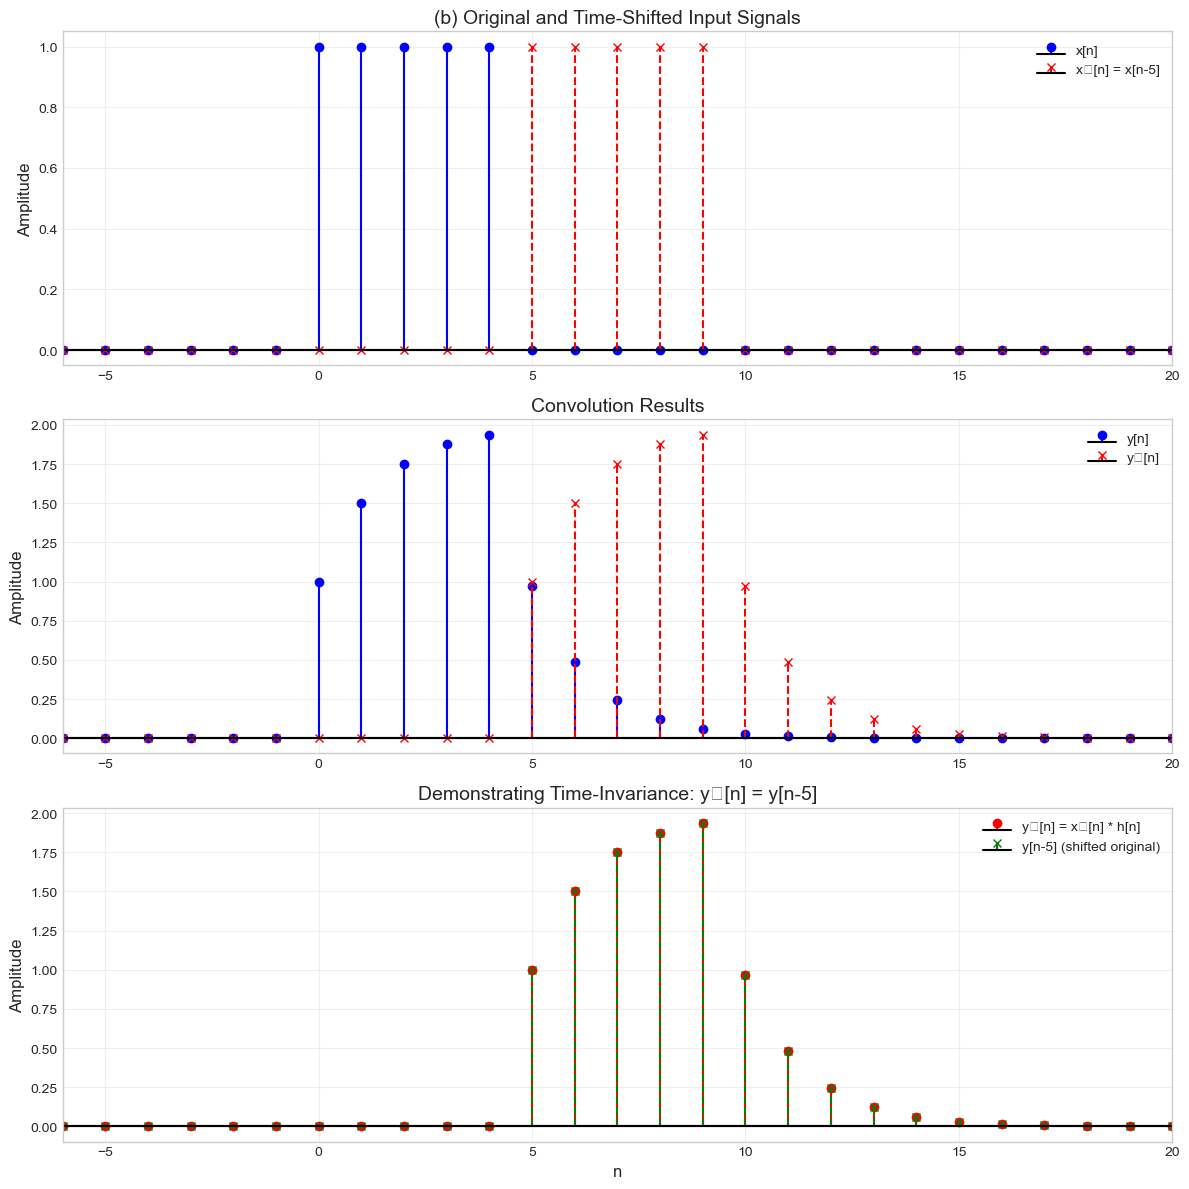


3. Part (c): 2D Convolution without padding and stride=1


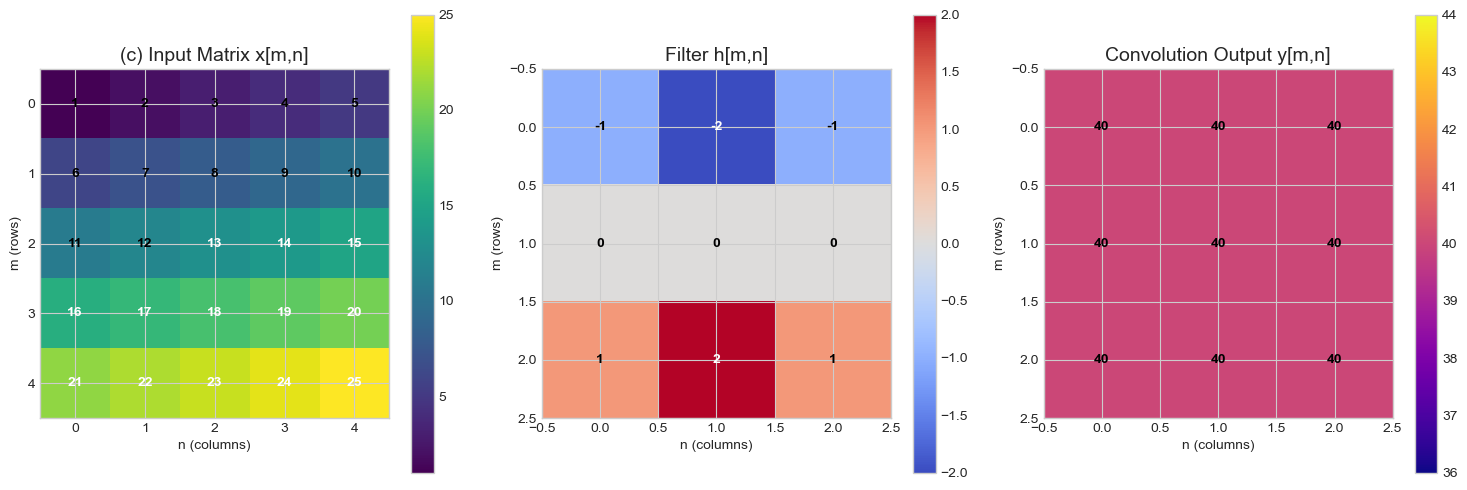

Input matrix x:
[[ 1.  2.  3.  4.  5.]
 [ 6.  7.  8.  9. 10.]
 [11. 12. 13. 14. 15.]
 [16. 17. 18. 19. 20.]
 [21. 22. 23. 24. 25.]]

Filter h:
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Convolution result y:
[[40. 40. 40.]
 [40. 40. 40.]
 [40. 40. 40.]]

4. Part (d): 2D Convolution with striding and padding


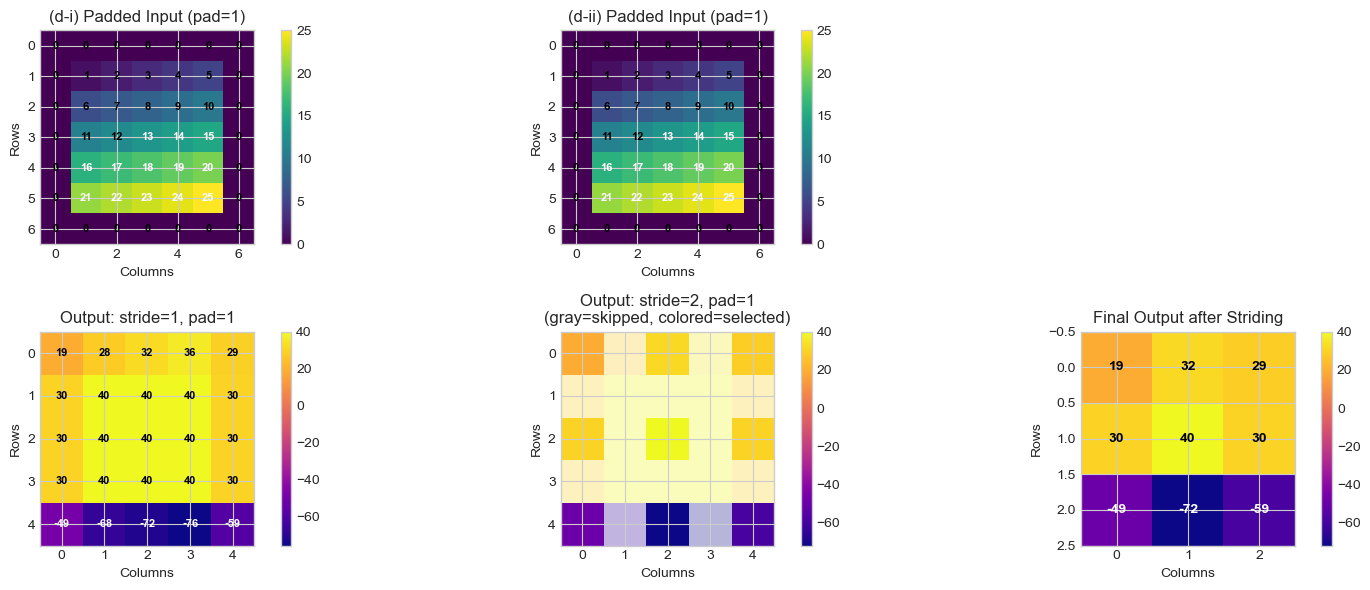

Case i - stride=1, pad=1:
Output shape: (5, 5)
Output matrix:
[[ 19.  28.  32.  36.  29.]
 [ 30.  40.  40.  40.  30.]
 [ 30.  40.  40.  40.  30.]
 [ 30.  40.  40.  40.  30.]
 [-49. -68. -72. -76. -59.]]

Case ii - stride=2, pad=1:
Output shape: (3, 3)
Output matrix:
[[ 19.  32.  29.]
 [ 30.  40.  30.]
 [-49. -72. -59.]]

All plots generated successfully!


In [6]:
# =============================================================================
# Main execution
# =============================================================================

if __name__ == "__main__":
    print("Generating all convolution plots...")
    print("=" * 60)
    
    # Run all parts
    print("\n1. Part (a): 1D Convolution of rectangular signal and exponential decay")
    part_a()
    
    print("\n2. Part (b): Time-shifted convolution demonstration")
    part_b()
    
    print("\n3. Part (c): 2D Convolution without padding and stride=1")
    part_c()
    
    print("\n4. Part (d): 2D Convolution with striding and padding")
    part_d()
    
    print("\nAll plots generated successfully!")